# 中文新闻分类模型对比实验

本 Notebook 使用 CLUE TNEWS 中文新闻标题数据集，比较四种模型：

1. **TF-IDF + LinearSVC**：传统机器学习基线。
2. **TextCNN**：从零训练的深度学习模型。
3. **Chinese RoBERTa + LoRA**：参数高效微调主实验。
4. **Chinese RoBERTa + Houlsby Adapter**：参数高效微调附加实验。

实验统一使用 15 类新闻标题分类、固定随机种子和相同的数据划分，报告 Accuracy、Macro-F1、Weighted-F1、训练时间、推理速度和可训练参数量。

数据先按 80%/10%/10% 分层划分训练、验证和测试集，再按类别进行可复现采样；正式实验默认每类最多取 1500/300/300 条（无 CUDA 时为 300/100/100），快速模式每类取 30/10/10 条。

研究问题：字符级 TF-IDF 能否有效分类中文标题？TextCNN 是否能从局部短语中获益？预训练语义表示是否提高 Macro-F1？LoRA 与 Adapter 的性能和参数、训练成本如何权衡？

> 默认配置适合 Colab/Kaggle GPU。首次运行时将 `INSTALL_DEPS` 改为 `True` 安装依赖；先用 `FAST_MODE=True` 完成冒烟测试，再关闭它进行正式实验。


## 1. 环境安装

`adapters` 用于 Houlsby Adapter 实验。如果只需要先运行前三个模型，可以暂时跳过 Adapter；正式实验建议在 GPU 环境中安装全部依赖。


In [1]:
# Colab/Kaggle 首次运行可设为 True；本地已有环境可保持 False
INSTALL_DEPS = True

if INSTALL_DEPS:
    import sys
    import subprocess
    packages = [
        "numpy>=1.24", "pandas>=2.0", "scikit-learn>=1.3",
        "matplotlib>=3.7", "seaborn>=0.12", "torch>=2.0",
        "datasets==2.19.1", "transformers==4.57.6", "peft==0.17.1",
        "accelerate>=0.28", "adapters==1.3.0", "jupyter",
    ]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
    print("Dependencies installed. Restart the runtime if a package import still fails.")
else:
    print("Dependency installation skipped. Set INSTALL_DEPS=True for a fresh Colab/Kaggle runtime.")


Dependencies installed. Restart the runtime if a package import still fails.


## 2. 导入库、配置与随机种子

In [2]:
import copy
import inspect
import json
import os
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import Dataset as HFDataset
from datasets import DatasetDict, load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset as TorchDataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments)
from peft import LoraConfig, TaskType, get_peft_model

try:
    from adapters import AdapterTrainer, AutoAdapterModel, DoubleSeqBnConfig
    ADAPTERS_AVAILABLE = True
except Exception as exc:
    ADAPTERS_AVAILABLE = False
    ADAPTERS_IMPORT_ERROR = repr(exc)

warnings.filterwarnings("ignore")
SEED = 42
FAST_MODE = False
# Set FAST_MODE=True for a quick end-to-end smoke test.
# Formal mode still uses a reproducible stratified subset; set limits to None to use all rows.
TRAIN_MAX_PER_CLASS = 30 if FAST_MODE else (1500 if torch.cuda.is_available() else 300)
EVAL_MAX_PER_CLASS = 10 if FAST_MODE else (300 if torch.cuda.is_available() else 100)
MAX_LENGTH = 64
NUM_LABELS = 15
MODEL_NAME = "hfl/chinese-roberta-wwm-ext"
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print(f"Device: {DEVICE}")
print(f"Adapters available: {ADAPTERS_AVAILABLE}")
if not ADAPTERS_AVAILABLE:
    print("Adapter experiment will be skipped until the `adapters` package is installed.")


Device: cuda
Adapters available: True


In [15]:
!wget -q https://github.com/StellarCN/scp_zh/raw/master/fonts/SimHei.ttf

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

fm.fontManager.addfont('SimHei.ttf')
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

## 3. 加载 CLUE TNEWS 并固定 80/10/10 分层划分

In [3]:
try:
    raw = load_dataset("clue", "tnews")
except Exception as first_error:
    # The CLUE Hub repo also publishes Parquet files; use them if the dataset builder is unavailable.
    print("Direct CLUE loader failed; falling back to the public TNEWS Parquet files.")
    print(type(first_error).__name__, str(first_error)[:300])
    tnews_url = "https://huggingface.co/datasets/clue/resolve/main/tnews"
    raw = load_dataset("parquet", data_files={
        "train": f"{tnews_url}/train-00000-of-00001.parquet",
        "validation": f"{tnews_url}/validation-00000-of-00001.parquet",
        "test": f"{tnews_url}/test-00000-of-00001.parquet",
    })
print(raw)
print("Columns:", raw["train"].column_names)

def load_and_split_data(raw_dataset, train_max_per_class, eval_max_per_class, seed=SEED):
    base = raw_dataset["train"]
    valid_mask = [0 <= int(y) < NUM_LABELS for y in base["label"]]
    base = base.select(np.flatnonzero(valid_mask).tolist())
    normalized_sentence = pd.Series(base["sentence"], dtype="string").fillna("").str.replace(r"\s+", "", regex=True)
    dedup_keep = ~normalized_sentence.duplicated(keep="first")
    base = base.select(np.flatnonzero(dedup_keep.to_numpy()).tolist())
    all_indices = np.arange(len(base))
    all_labels = np.asarray(base["label"], dtype=int)
    train_idx, temp_idx = train_test_split(
        all_indices, test_size=0.2, random_state=seed, stratify=all_labels
    )
    temp_labels = all_labels[temp_idx]
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.5, random_state=seed, stratify=temp_labels
    )
    def cap_per_class(split_data, max_per_class, split_seed):
        if max_per_class is None:
            return split_data
        rng = np.random.default_rng(split_seed)
        labels = np.asarray(split_data["label"], dtype=int)
        selected = []
        for label in sorted(np.unique(labels)):
            candidates = np.flatnonzero(labels == label)
            take = min(max_per_class, len(candidates))
            selected.extend(rng.choice(candidates, size=take, replace=False).tolist())
        return split_data.select(sorted(selected))
    splits = DatasetDict({
        "train": cap_per_class(base.select(train_idx.tolist()), train_max_per_class, seed),
        "validation": cap_per_class(base.select(val_idx.tolist()), eval_max_per_class, seed + 1),
        "test": cap_per_class(base.select(test_idx.tolist()), eval_max_per_class, seed + 2),
    })
    return splits, train_idx, val_idx, test_idx

dataset, train_idx, val_idx, test_idx = load_and_split_data(
    raw, TRAIN_MAX_PER_CLASS, EVAL_MAX_PER_CLASS, seed=SEED
)
base = raw["train"]

# 保证 FAST_MODE 和正式模式都使用相同的标签编码。
feature = raw["train"].features.get("label")
label_names = list(getattr(feature, "names", []) or [])
if len(label_names) != NUM_LABELS:
    label_names = [f"class_{i}" for i in range(NUM_LABELS)]
category_names = {
    "100": "故事", "101": "文化", "102": "娱乐", "103": "体育",
    "104": "财经", "106": "房产", "107": "汽车", "108": "教育",
    "109": "科技", "110": "军事", "112": "旅游", "113": "国际",
    "114": "证券", "115": "农业", "116": "电竞",
}
label_names = [category_names.get(str(name), str(name)) for name in label_names]
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for i, name in enumerate(label_names)}
print({split: len(ds) for split, ds in dataset.items()})
display(pd.DataFrame({"label": range(NUM_LABELS), "name": label_names}))
display(pd.DataFrame({split: np.bincount(np.asarray(ds["label"], dtype=int), minlength=NUM_LABELS) for split, ds in dataset.items()}, index=label_names))


Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/53360 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 53360
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 10000
    })
})
Columns: ['sentence', 'label', 'idx']
{'train': 20585, 'validation': 3906, 'test': 3904}


,label,name
0,0,故事
1,1,文化
2,2,娱乐
3,3,体育
4,4,财经
5,5,房产
6,6,汽车
7,7,教育
8,8,科技
9,9,军事


,train,validation,test
故事,887,111,111
文化,1500,300,300
娱乐,1500,300,300
体育,1500,300,300
财经,1500,300,300
房产,1500,192,191
汽车,1500,300,300
教育,1500,300,300
科技,1500,300,300
军事,1500,300,300


## 4. 统一评价函数与实验记录

In [4]:
results = []
histories = {}
predictions = {}
reports = {}
parameter_audit = {}

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return int(total), int(trainable)

def metric_dict(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }

def evaluate_model(y_true, y_pred):
    metrics = metric_dict(y_true, y_pred)
    report = classification_report(
        y_true, y_pred, labels=list(range(NUM_LABELS)), target_names=label_names,
        output_dict=True, zero_division=0
    )
    return metrics, report

def record_result(name, y_true, y_pred, total_params, trainable_params, train_seconds, inference_seconds, history=None):
    metrics, report = evaluate_model(y_true, y_pred)
    results.append({
        "model": name, **metrics,
        "trainable_params": int(trainable_params),
        "total_params": int(total_params),
        "train_seconds": float(train_seconds),
        "inference_ms_per_sample": float(inference_seconds * 1000 / max(len(y_true), 1)),
    })
    predictions[name] = np.asarray(y_pred)
    reports[name] = report
    if history is not None:
        histories[name] = history
    parameter_audit[name] = {"total": int(total_params), "trainable": int(trainable_params)}
    print(name, metrics)
    return metrics

def show_result_table():
    return pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)

def plot_training_curves(histories, output_path):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for name, history in histories.items():
        if history.get("train_loss"):
            axes[0].plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o", label=name)
        if history.get("val_macro_f1"):
            axes[1].plot(range(1, len(history["val_macro_f1"]) + 1), history["val_macro_f1"], marker="o", label=name)
    axes[0].set(title="Training Loss", xlabel="Epoch / logging step", ylabel="Cross-entropy loss")
    axes[1].set(title="Validation Macro-F1", xlabel="Epoch / evaluation step", ylabel="Macro-F1")
    for ax in axes:
        if ax.lines:
            ax.legend()
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    return fig

def plot_confusion_matrix(y_true, y_pred, labels, output_path, title):
    matrix = confusion_matrix(y_true, y_pred, labels=list(range(NUM_LABELS)))
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(matrix, annot=False, cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set(title=title, xlabel="Predicted", ylabel="True")
    fig.tight_layout()
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    return matrix, fig


## 5. TF-IDF + LinearSVC 基线

In [5]:
train_texts = list(dataset["train"]["sentence"])
val_texts = list(dataset["validation"]["sentence"])
test_texts = list(dataset["test"]["sentence"])
y_train = np.asarray(dataset["train"]["label"], dtype=int)
y_val = np.asarray(dataset["validation"]["label"], dtype=int)
y_test = np.asarray(dataset["test"]["label"], dtype=int)

def train_svm(train_texts, y_train, test_texts, y_test):
    start = time.perf_counter()
    vectorizer = TfidfVectorizer(
        analyzer="char", ngram_range=(2, 5), min_df=2,
        max_features=80000, sublinear_tf=True
    )
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    classifier = LinearSVC(C=2.0)
    classifier.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start
    infer_start = time.perf_counter()
    predictions = classifier.predict(X_test)
    inference_seconds = time.perf_counter() - infer_start
    return vectorizer, classifier, predictions, train_seconds, inference_seconds

vectorizer, svm, svm_pred, svm_train_seconds, svm_infer_seconds = train_svm(
    train_texts, y_train, test_texts, y_test
)
svm_param_count = int(svm.coef_.size + len(vectorizer.vocabulary_))
record_result("TF-IDF + LinearSVC", y_test, svm_pred, svm_param_count, int(svm.coef_.size), svm_train_seconds, svm_infer_seconds)
with open(OUTPUT_DIR / "tfidf_linearsvc.pkl", "wb") as f:
    import pickle
    pickle.dump({"vectorizer": vectorizer, "classifier": svm}, f)
print("TF-IDF vocabulary size:", len(vectorizer.vocabulary_))
display(show_result_table())


TF-IDF + LinearSVC {'accuracy': 0.4731045081967213, 'macro_precision': 0.45920569460909005, 'macro_recall': 0.4638086573899223, 'macro_f1': 0.4607649475174397, 'weighted_f1': 0.473636844730408}
TF-IDF vocabulary size: 80000


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,trainable_params,total_params,train_seconds,inference_ms_per_sample
0,TF-IDF + LinearSVC,0.473105,0.459206,0.463809,0.460765,0.473637,1200000,1280000,18.773595,0.001158


## 6. TextCNN：从零训练的深度学习模型

In [6]:
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
MAX_VOCAB = 20000
TEXTCNN_MAX_LEN = 64

def build_char_vocab(texts, max_vocab=MAX_VOCAB):
    counts = {}
    for text in texts:
        for char in str(text):
            counts[char] = counts.get(char, 0) + 1
    chars = sorted(counts, key=counts.get, reverse=True)[: max_vocab - 2]
    return {PAD_TOKEN: 0, UNK_TOKEN: 1, **{char: i + 2 for i, char in enumerate(chars)}}

char_vocab = build_char_vocab(train_texts)

def encode_chars(text, vocab=char_vocab, max_len=TEXTCNN_MAX_LEN):
    ids = [vocab.get(char, vocab[UNK_TOKEN]) for char in str(text)[:max_len]]
    return ids + [vocab[PAD_TOKEN]] * (max_len - len(ids))

class TextCNNDataset(TorchDataset):
    def __init__(self, texts, labels):
        self.input_ids = torch.tensor([encode_chars(t) for t in texts], dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return {"input_ids": self.input_ids[index], "labels": self.labels[index]}

class TextCNN(nn.Module):
    def __init__(self, vocab_size, num_labels=NUM_LABELS, embed_dim=128, channels=128, kernels=(3, 4, 5)):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(embed_dim, channels, kernel) for kernel in kernels])
        self.dropout = nn.Dropout(0.5)
        self.classifier = nn.Linear(channels * len(kernels), num_labels)
    def forward(self, input_ids):
        embedded = self.embedding(input_ids).transpose(1, 2)
        pooled = [F.relu(conv(embedded)).max(dim=2).values for conv in self.convs]
        return self.classifier(self.dropout(torch.cat(pooled, dim=1)))

def textcnn_eval(model, loader):
    model.eval()
    all_logits, all_labels, losses = [], [], []
    with torch.no_grad():
        for batch in loader:
            labels = batch["labels"].to(DEVICE)
            logits = model(batch["input_ids"].to(DEVICE))
            losses.append(F.cross_entropy(logits, labels).item())
            all_logits.append(logits.detach().cpu())
            all_labels.append(labels.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy()
    preds = logits.argmax(axis=1)
    return float(np.mean(losses)), preds, metric_dict(labels, preds)

def train_textcnn_model(train_dataset, val_dataset, epochs=8):
    model = TextCNN(len(char_vocab)).to(DEVICE)
    train_loader = DataLoader(train_dataset, batch_size=64 if DEVICE.type == "cuda" else 32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=128 if DEVICE.type == "cuda" else 64)
    optimizer = AdamW(model.parameters(), lr=1e-3)
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_macro_f1": []}
    best_f1, best_state, stale = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            labels = batch["labels"].to(DEVICE)
            logits = model(batch["input_ids"].to(DEVICE))
            loss = F.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        val_loss, _, val_metrics = textcnn_eval(model, val_loader)
        history["epoch"].append(epoch)
        history["train_loss"].append(float(np.mean(losses)))
        history["val_loss"].append(val_loss)
        history["val_macro_f1"].append(val_metrics["macro_f1"])
        print(f"epoch={epoch} train_loss={np.mean(losses):.4f} val_loss={val_loss:.4f} val_macro_f1={val_metrics['macro_f1']:.4f}")
        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= 2:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

def train_textcnn(train_dataset, val_dataset, epochs=8):
    return train_textcnn_model(train_dataset, val_dataset, epochs=epochs)

textcnn_train_ds = TextCNNDataset(train_texts, y_train)
textcnn_val_ds = TextCNNDataset(val_texts, y_val)
textcnn_test_ds = TextCNNDataset(test_texts, y_test)
textcnn_start = time.perf_counter()
textcnn_model, textcnn_history = train_textcnn(textcnn_train_ds, textcnn_val_ds, epochs=2 if FAST_MODE else 8)
textcnn_train_seconds = time.perf_counter() - textcnn_start
textcnn_test_loader = DataLoader(textcnn_test_ds, batch_size=128 if DEVICE.type == "cuda" else 64)
textcnn_infer_start = time.perf_counter()
_, textcnn_pred, _ = textcnn_eval(textcnn_model, textcnn_test_loader)
textcnn_infer_seconds = time.perf_counter() - textcnn_infer_start
textcnn_total, textcnn_trainable = count_parameters(textcnn_model)
record_result("TextCNN", y_test, textcnn_pred, textcnn_total, textcnn_trainable, textcnn_train_seconds, textcnn_infer_seconds, textcnn_history)
torch.save(textcnn_model.state_dict(), OUTPUT_DIR / "textcnn.pt")
display(show_result_table())


epoch=1 train_loss=2.4433 val_loss=1.9658 val_macro_f1=0.3606
epoch=2 train_loss=1.9530 val_loss=1.7816 val_macro_f1=0.4366
epoch=3 train_loss=1.7429 val_loss=1.7037 val_macro_f1=0.4433
epoch=4 train_loss=1.5818 val_loss=1.6762 val_macro_f1=0.4549
epoch=5 train_loss=1.4268 val_loss=1.6447 val_macro_f1=0.4432
epoch=6 train_loss=1.2863 val_loss=1.6401 val_macro_f1=0.4583
epoch=7 train_loss=1.1557 val_loss=1.6493 val_macro_f1=0.4554
epoch=8 train_loss=1.0551 val_loss=1.6680 val_macro_f1=0.4614
TextCNN {'accuracy': 0.4707991803278688, 'macro_precision': 0.4757987824964781, 'macro_recall': 0.46306853506864804, 'macro_f1': 0.46478884680051574, 'weighted_f1': 0.47146699979349554}


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,trainable_params,total_params,train_seconds,inference_ms_per_sample
0,TextCNN,0.470799,0.475799,0.463069,0.464789,0.471467,741903,741903,23.903612,0.034923
1,TF-IDF + LinearSVC,0.473105,0.459206,0.463809,0.460765,0.473637,1200000,1280000,18.773595,0.001158


## 7. 预训练模型数据处理

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
def tokenize_batch(batch):
    return tokenizer(batch["sentence"], truncation=True, max_length=MAX_LENGTH)

tokenized = dataset.map(tokenize_batch, batched=True, desc="Tokenizing")
tokenized = tokenized.rename_column("label", "labels")
allowed_columns = set(tokenizer.model_input_names) | {"labels"}
for split in tokenized:
    remove_columns = [c for c in tokenized[split].column_names if c not in allowed_columns]
    if remove_columns:
        tokenized[split] = tokenized[split].remove_columns(remove_columns)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8 if DEVICE.type == "cuda" else None)
print(tokenized)
display(tokenizer(train_texts[0], truncation=True, max_length=MAX_LENGTH))


tokenizer_config.json:   0%|          | 0.00/19.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

...

Tokenizing:   0%|          | 0/20585 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/3906 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/3904 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 20585
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3906
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3904
    })
})


{'input_ids': [101, 1812, 3449, 7027, 8038, 6006, 4197, 1762, 3616, 1094, 3300, 6890, 2742, 8024, 852, 2769, 2190, 2349, 7944, 6821, 702, 6612, 2108, 4638, 6134, 4385, 4007, 2692, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

## 8. Hugging Face Trainer 通用配置

In [8]:
def make_training_args(output_dir, learning_rate=2e-4, epochs=None):
    epochs = epochs or (1 if FAST_MODE else 3)
    kwargs = dict(
        output_dir=str(output_dir),
        per_device_train_batch_size=8 if DEVICE.type == "cuda" else 4,
        per_device_eval_batch_size=16 if DEVICE.type == "cuda" else 8,
        gradient_accumulation_steps=2 if DEVICE.type == "cuda" else 1,
        learning_rate=learning_rate,
        weight_decay=0.01,
        num_train_epochs=epochs,
        logging_strategy="epoch",
        save_strategy="no",
        report_to="none",
        seed=SEED,
        data_seed=SEED,
        fp16=DEVICE.type == "cuda",
        dataloader_num_workers=0,
        remove_unused_columns=True,
    )
    signature = inspect.signature(TrainingArguments.__init__).parameters
    if "eval_strategy" in signature:
        kwargs["eval_strategy"] = "epoch"
    else:
        kwargs["evaluation_strategy"] = "epoch"
    return TrainingArguments(**kwargs)

def hf_compute_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    preds = np.argmax(logits, axis=-1)
    return metric_dict(labels, preds)

def extract_history(trainer):
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_macro_f1": []}
    for row in trainer.state.log_history:
        if "loss" in row and "eval_loss" not in row:
            history["epoch"].append(row.get("epoch"))
            history["train_loss"].append(row.get("loss"))
        if "eval_macro_f1" in row:
            history["val_loss"].append(row.get("eval_loss"))
            history["val_macro_f1"].append(row.get("eval_macro_f1"))
    return history

def run_hf_experiment(model, name, trainer_cls=Trainer, output_subdir=None):
    args = make_training_args(OUTPUT_DIR / (output_subdir or name.replace(" ", "_")))
    trainer = trainer_cls(
        model=model, args=args,
        train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
        data_collator=data_collator, compute_metrics=hf_compute_metrics,
    )
    train_start = time.perf_counter()
    trainer.train()
    train_seconds = time.perf_counter() - train_start
    infer_start = time.perf_counter()
    output = trainer.predict(tokenized["test"])
    inference_seconds = time.perf_counter() - infer_start
    logits = output.predictions[0] if isinstance(output.predictions, tuple) else output.predictions
    preds = np.argmax(logits, axis=-1)
    total, trainable = count_parameters(model)
    history = extract_history(trainer)
    record_result(name, y_test, preds, total, trainable, train_seconds, inference_seconds, history)
    return trainer, model


## 9. Chinese RoBERTa + LoRA

In [9]:
def train_lora_classifier():
    set_seed()
    lora_base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True
    )
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
        target_modules=["query", "value"], modules_to_save=["classifier"]
    )
    model = get_peft_model(lora_base, lora_config)
    model.print_trainable_parameters()
    return run_hf_experiment(model, "RoBERTa + LoRA", output_subdir="roberta_lora")

lora_trainer, lora_model = train_lora_classifier()
lora_model.save_pretrained(OUTPUT_DIR / "roberta_lora")
tokenizer.save_pretrained(OUTPUT_DIR / "roberta_lora")
display(show_result_table())


pytorch_model.bin:   0%|          | 0.00/412M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at hfl/chinese-roberta-wwm-ext and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 306,447 || all params: 102,585,630 || trainable%: 0.2987


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,1.570300,1.349222,0.554019,0.555911,0.548081,0.540704,0.553359
2,1.318400,1.294204,0.563748,0.551940,0.579944,0.559726,0.564257
3,1.265700,1.282281,0.563492,0.559692,0.577330,0.565512,0.563496


RoBERTa + LoRA {'accuracy': 0.5676229508196722, 'macro_precision': 0.560588992030419, 'macro_recall': 0.5736815253612872, 'macro_f1': 0.5643166456179436, 'weighted_f1': 0.5695044352842139}


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,trainable_params,total_params,train_seconds,inference_ms_per_sample
0,RoBERTa + LoRA,0.567623,0.560589,0.573682,0.564317,0.569504,306447,102585630,529.172486,1.310686
1,TextCNN,0.470799,0.475799,0.463069,0.464789,0.471467,741903,741903,23.903612,0.034923
2,TF-IDF + LinearSVC,0.473105,0.459206,0.463809,0.460765,0.473637,1200000,1280000,18.773595,0.001158


## 10. Chinese RoBERTa + Houlsby Adapter

In [10]:
def train_adapter_classifier():
    if not ADAPTERS_AVAILABLE:
        raise RuntimeError("Install adapters==1.3.0 to run the Adapter experiment.")
    set_seed()
    model = AutoAdapterModel.from_pretrained(MODEL_NAME)
    adapter_name = "tnews_houlsby"
    model.add_adapter(adapter_name, config=DoubleSeqBnConfig(reduction_factor=16))
    model.add_classification_head(adapter_name, num_labels=NUM_LABELS, id2label=id2label)
    model.train_adapter(adapter_name)
    model.set_active_adapters(adapter_name)
    if hasattr(model, "set_active_head"):
        model.set_active_head(adapter_name)
    return run_hf_experiment(
        model, "RoBERTa + Houlsby Adapter",
        trainer_cls=AdapterTrainer, output_subdir="roberta_adapter"
    )

if ADAPTERS_AVAILABLE:
    adapter_trainer, adapter_model = train_adapter_classifier()
    adapter_model.save_pretrained(OUTPUT_DIR / "roberta_adapter")
else:
    print("Skipping Adapter experiment. Install `adapters>=1.2` and rerun this section.")
    print("Import error:", globals().get("ADAPTERS_IMPORT_ERROR", "unknown"))


Some weights of BertAdapterModel were not initialized from the model checkpoint at hfl/chinese-roberta-wwm-ext and are newly initialized: ['heads.default.3.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,2.811300,1.277642,0.561956,0.565683,0.570620,0.559517,0.562195
2,2.434500,1.234374,0.566820,0.556733,0.585742,0.564697,0.567639
3,2.252700,1.223179,0.575525,0.573925,0.583585,0.576340,0.575864


RoBERTa + Houlsby Adapter {'accuracy': 0.5701844262295082, 'macro_precision': 0.5599590724185697, 'macro_recall': 0.5707051411651208, 'macro_f1': 0.563249827972891, 'weighted_f1': 0.5708778866757759}


## 11. 结果汇总与模型对比

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,trainable_params,total_params,train_seconds,inference_ms_per_sample
0,RoBERTa + LoRA,0.5676,0.560589,0.573682,0.5643,0.5695,306447,102585630,529.17,1.311
1,RoBERTa + Houlsby Adapter,0.5702,0.559959,0.570705,0.5632,0.5709,3004439,105272087,507.39,1.998
2,TextCNN,0.4708,0.475799,0.463069,0.4648,0.4715,741903,741903,23.90,0.035
3,TF-IDF + LinearSVC,0.4731,0.459206,0.463809,0.4608,0.4736,1200000,1280000,18.77,0.001


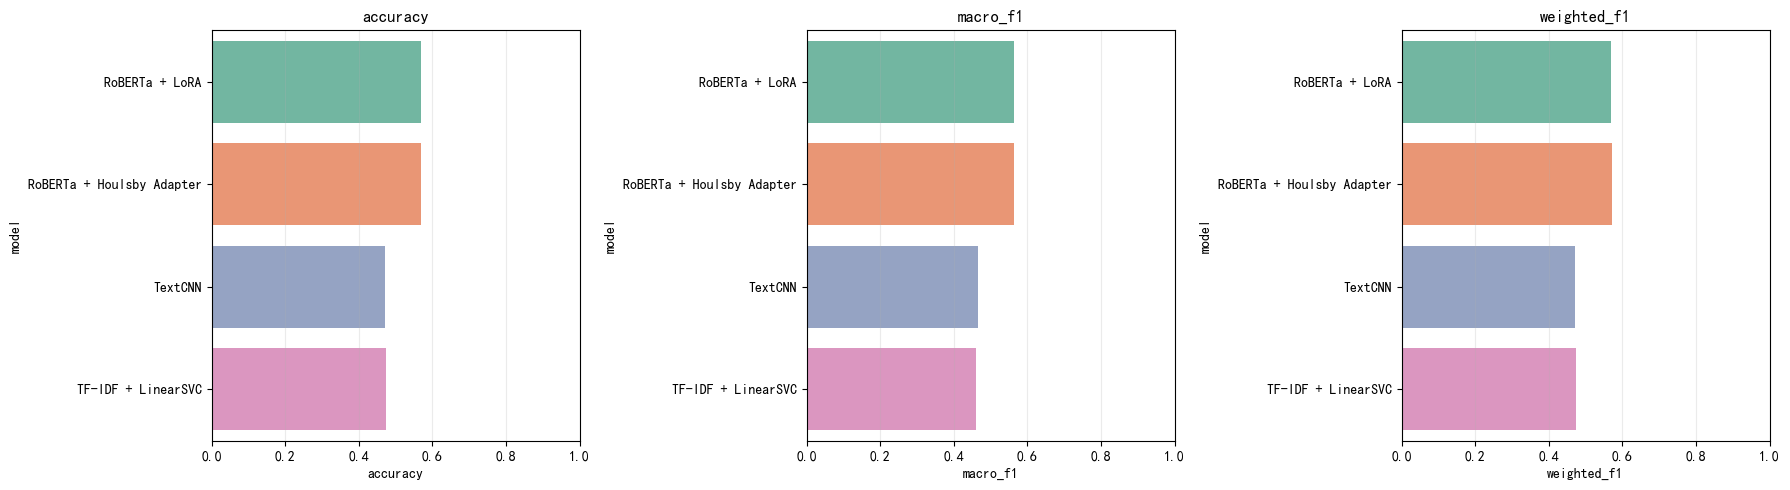

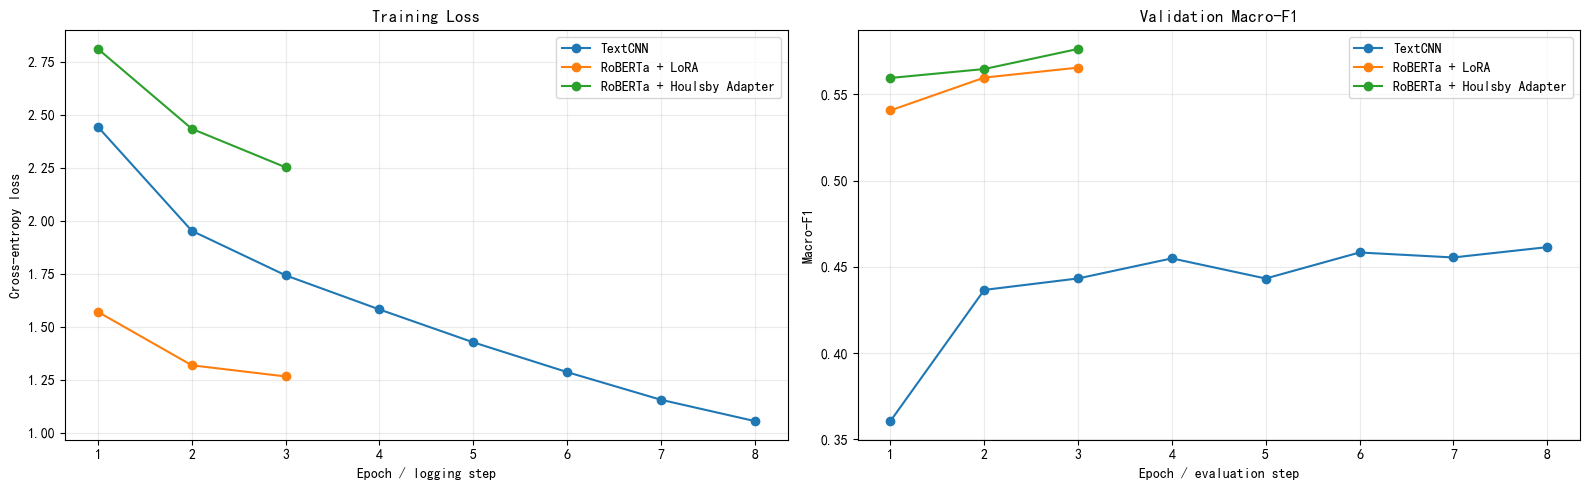

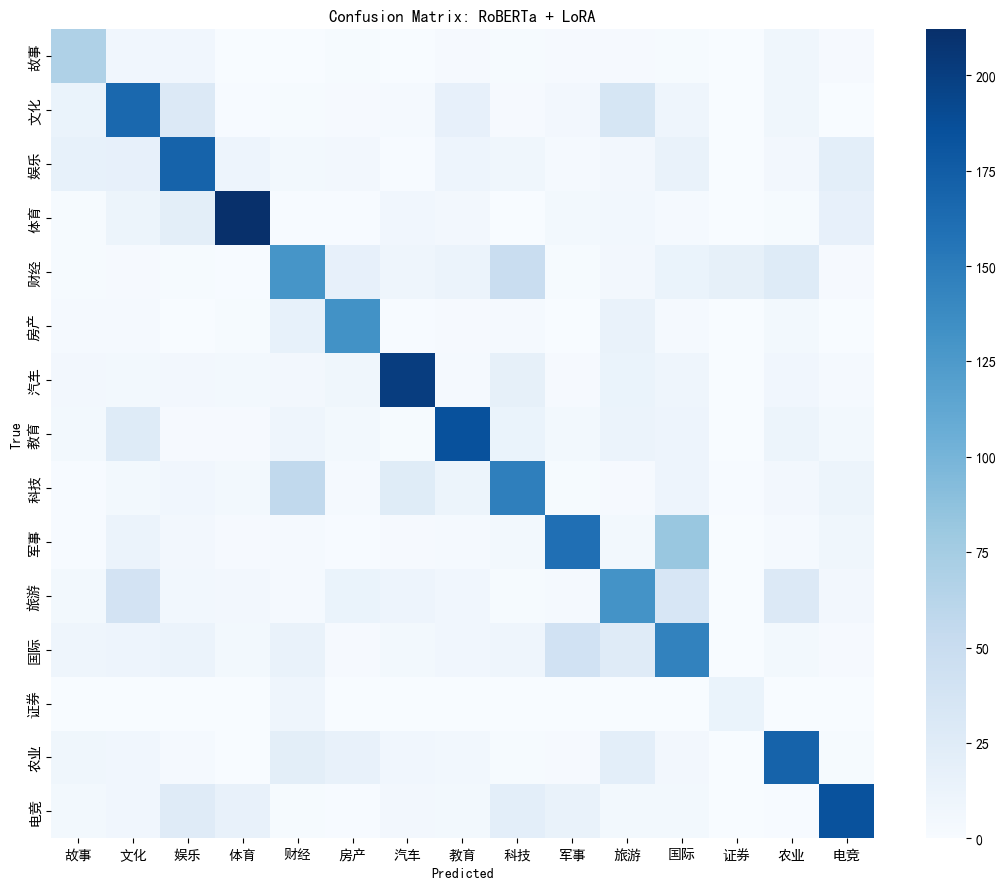

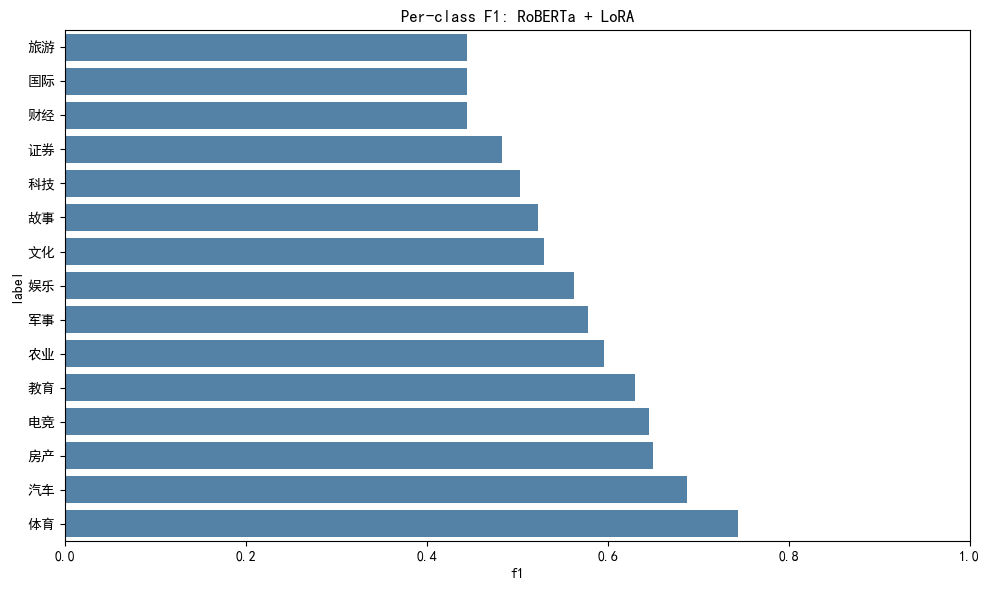

In [16]:
results_df = show_result_table()
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False, encoding="utf-8-sig")
with open(OUTPUT_DIR / "classification_reports.json", "w", encoding="utf-8") as f:
    json.dump(reports, f, ensure_ascii=False, indent=2, default=float)
display(results_df.style.format({
    "accuracy": "{:.4f}", "macro_f1": "{:.4f}",
    "weighted_f1": "{:.4f}", "train_seconds": "{:.2f}",
    "inference_ms_per_sample": "{:.3f}"
}))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["accuracy", "macro_f1", "weighted_f1"]):
    sns.barplot(data=results_df, x=metric, y="model", ax=ax, palette="Set2")
    ax.set_title(metric)
    ax.set_xlim(0, 1)
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metric_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

plot_training_curves(histories, OUTPUT_DIR / "training_curves.png")

if not results_df.empty:
    best_name = results_df.iloc[0]["model"]
    cm, _ = plot_confusion_matrix(y_test, predictions[best_name], label_names, OUTPUT_DIR / "best_confusion_matrix.png", f"Confusion Matrix: {best_name}")

    best_report = reports[best_name]
    per_class = pd.DataFrame([
        {"label": label, "f1": best_report[label]["f1-score"], "support": best_report[label]["support"]}
        for label in label_names
    ]).sort_values("f1")
    plt.figure(figsize=(10, 6))
    sns.barplot(data=per_class, x="f1", y="label", color="steelblue")
    plt.xlim(0, 1)
    plt.title(f"Per-class F1: {best_name}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "best_per_class_f1.png", dpi=160, bbox_inches="tight")
    plt.show()


## 12. 基于实际结果的自动分析

In [12]:
def analyze_results(results_df):
    if results_df.empty:
        return
    best = results_df.iloc[0]
    baseline = results_df[results_df["model"] == "TF-IDF + LinearSVC"]
    print(f"Macro-F1 最优模型：{best['model']} ({best['macro_f1']:.4f})")
    if not baseline.empty:
        delta = best["macro_f1"] - baseline.iloc[0]["macro_f1"]
        print(f"相对 TF-IDF 基线的 Macro-F1 变化：{delta:+.4f}")
    efficient = results_df[results_df["model"].str.contains("LoRA|Adapter", regex=True)]
    if not efficient.empty:
        efficient = efficient.copy()
        efficient["trainable_ratio"] = efficient["trainable_params"] / efficient["total_params"].clip(lower=1)
        display(efficient[["model", "accuracy", "macro_f1", "trainable_params", "total_params", "trainable_ratio", "train_seconds", "inference_ms_per_sample"]])
    class_f1 = pd.DataFrame([
        {"label": label, "f1": reports[best["model"]][label]["f1-score"]}
        for label in label_names
    ]).sort_values("f1")
    print("易混类别（最优模型 F1 最低）：", class_f1.head(3).to_dict("records"))
    print("解释时请结合这些类别的标题内容、Macro-F1 与训练成本，不要只看 Accuracy。")

analyze_results(results_df)


Macro-F1 最优模型：RoBERTa + LoRA (0.5643)
相对 TF-IDF 基线的 Macro-F1 变化：+0.1036


,model,accuracy,macro_f1,trainable_params,total_params,trainable_ratio,train_seconds,inference_ms_per_sample
0,RoBERTa + LoRA,0.567623,0.564317,306447,102585630,0.002987,529.172486,1.310686
1,RoBERTa + Houlsby Adapter,0.570184,0.563250,3004439,105272087,0.028540,507.386230,1.997837


易混类别（最优模型 F1 最低）： [{'label': '旅游', 'f1': 0.4440677966101695}, {'label': '国际', 'f1': 0.444104134762634}, {'label': '财经', 'f1': 0.4444444444444444}]
解释时请结合这些类别的标题内容、Macro-F1 与训练成本，不要只看 Accuracy。


## 13. 典型错误样本与分类报告

In [13]:
def analyze_errors(model_name, max_rows=8):
    pred = predictions[model_name]
    frame = pd.DataFrame({
        "sentence": test_texts,
        "true_id": y_test,
        "pred_id": pred,
    })
    frame["true_label"] = frame["true_id"].map(dict(enumerate(label_names)))
    frame["pred_label"] = frame["pred_id"].map(dict(enumerate(label_names)))
    return frame[frame.true_id != frame.pred_id].head(max_rows)

error_tables = {}
for model_name in results_df["model"]:
    print(f"\n--- {model_name} ---")
    error_tables[model_name] = analyze_errors(model_name, max_rows=len(test_texts))
    error_tables[model_name].to_csv(OUTPUT_DIR / f"errors_{model_name.replace(' ', '_').replace('/', '_')}.csv", index=False, encoding="utf-8-sig")
    display(error_tables[model_name].head(8))
    display(pd.DataFrame(reports[model_name]).T.round(4).head(NUM_LABELS))



--- RoBERTa + LoRA ---


,sentence,true_id,pred_id,true_label,pred_label
1,如果您看了女博士面容忘了看字，不是小编的错,1,2,文化,娱乐
3,剃刀和卓越哪一个比较好？,14,8,电竞,科技
4,信用时代！芝麻信用分越高，你说获得的福利越多！,5,8,房产,科技
8,山东国惠&优客工场战略合作签约暨鲁勤时代·拾光里奠基仪式举行,4,5,财经,房产
13,怎样把手机上的电视剧转放到电视上？,8,14,科技,电竞
18,亦必如昔谜题（十一）,14,1,电竞,文化
19,一季度印度动力煤进口量同比增15%以上,11,4,国际,财经
29,战狼2和红海行动谁才能配的上50亿票房？,9,2,军事,娱乐


,precision,recall,f1-score,support
故事,0.4564,0.6126,0.5231,111.0
文化,0.5076,0.5533,0.5295,300.0
娱乐,0.5592,0.5667,0.5629,300.0
体育,0.7852,0.7067,0.7439,300.0
财经,0.4561,0.4333,0.4444,300.0
房产,0.6140,0.6911,0.6502,191.0
汽车,0.7053,0.6700,0.6872,300.0
教育,0.6446,0.6167,0.6303,300.0
科技,0.5121,0.4933,0.5025,300.0
军事,0.6324,0.5333,0.5787,300.0



--- RoBERTa + Houlsby Adapter ---


,sentence,true_id,pred_id,true_label,pred_label
1,如果您看了女博士面容忘了看字，不是小编的错,1,0,文化,故事
3,剃刀和卓越哪一个比较好？,14,8,电竞,科技
4,信用时代！芝麻信用分越高，你说获得的福利越多！,5,8,房产,科技
8,山东国惠&优客工场战略合作签约暨鲁勤时代·拾光里奠基仪式举行,4,5,财经,房产
13,怎样把手机上的电视剧转放到电视上？,8,2,科技,娱乐
15,这个小村子靠屠蛇为生，蛇骨堆积如山，蛇见了当地人转身就逃,13,0,农业,故事
17,如何应付 “贸易战”？不要反应过度,11,9,国际,军事
18,亦必如昔谜题（十一）,14,1,电竞,文化


...

,sentence,true_id,pred_id,true_label,pred_label
1,如果您看了女博士面容忘了看字，不是小编的错,1,0,文化,故事
3,剃刀和卓越哪一个比较好？,14,3,电竞,体育
4,信用时代！芝麻信用分越高，你说获得的福利越多！,5,4,房产,财经
7,赌命鬼找替身，想不到一口舌尖血，让他到磨坊磨了二十年的老豆腐,0,2,故事,娱乐
8,山东国惠&优客工场战略合作签约暨鲁勤时代·拾光里奠基仪式举行,4,1,财经,文化
16,公司钥匙丢了，千万别去自己去配一把，分享真实经历，很现实！,0,4,故事,财经
17,如何应付 “贸易战”？不要反应过度,11,4,国际,财经
18,亦必如昔谜题（十一）,14,13,电竞,农业


,precision,recall,f1-score,support
故事,0.3830,0.4865,0.4286,111.0
文化,0.4073,0.4467,0.4261,300.0
娱乐,0.4099,0.4400,0.4244,300.0
体育,0.6507,0.5900,0.6189,300.0
财经,0.3768,0.4333,0.4031,300.0
房产,0.4844,0.5707,0.5240,191.0
汽车,0.6706,0.5700,0.6162,300.0
教育,0.4917,0.5900,0.5364,300.0
科技,0.3595,0.3667,0.3630,300.0
军事,0.5487,0.4133,0.4715,300.0



--- TF-IDF + LinearSVC ---


,sentence,true_id,pred_id,true_label,pred_label
1,如果您看了女博士面容忘了看字，不是小编的错,1,2,文化,娱乐
3,剃刀和卓越哪一个比较好？,14,13,电竞,农业
4,信用时代！芝麻信用分越高，你说获得的福利越多！,5,4,房产,财经
7,赌命鬼找替身，想不到一口舌尖血，让他到磨坊磨了二十年的老豆腐,0,13,故事,农业
8,山东国惠&优客工场战略合作签约暨鲁勤时代·拾光里奠基仪式举行,4,8,财经,科技
11,如何看待“梅西是体系球员”的观点？你认为这个说法有道理吗？,3,10,体育,旅游
12,如何看待美国总统连续撕毁美国签署的国际协议的举动？,11,9,国际,军事
13,怎样把手机上的电视剧转放到电视上？,8,2,科技,娱乐


,precision,recall,f1-score,support
故事,0.3846,0.4505,0.4149,111.0
文化,0.4158,0.4033,0.4095,300.0
娱乐,0.4781,0.4733,0.4757,300.0
体育,0.6836,0.6267,0.6539,300.0
财经,0.3759,0.3433,0.3589,300.0
房产,0.4890,0.5812,0.5311,191.0
汽车,0.5845,0.5767,0.5805,300.0
教育,0.5793,0.5600,0.5695,300.0
科技,0.3692,0.4000,0.3840,300.0
军事,0.4880,0.4733,0.4805,300.0


## 14. 自动检查与结果分析提示

下面的检查用于确认实验没有数据泄漏、标签维度正确，并确认参数高效微调确实只训练少量参数。最终报告可根据实际结果讨论：

- 字符级 TF-IDF 是否已经捕捉了新闻标题中的关键词和固定短语；
- TextCNN 是否利用局部 n-gram 模式获得较好的分类效果；
- RoBERTa 是否因为上下文语义建模而优于传统模型；
- LoRA 与 Adapter 在 Macro-F1、训练时间和可训练参数量之间的权衡；
- 混淆矩阵中最容易混淆的新闻类别及其可能原因。


In [14]:
# 数据划分互斥性与类别完整性
assert set(train_idx).isdisjoint(set(val_idx))
assert set(train_idx).isdisjoint(set(test_idx))
assert set(val_idx).isdisjoint(set(test_idx))
assert set(train_texts).isdisjoint(set(val_texts))
assert set(train_texts).isdisjoint(set(test_texts))
assert set(val_texts).isdisjoint(set(test_texts))
assert set(np.unique(y_train)) == set(range(NUM_LABELS))
assert set(np.unique(y_val)) == set(range(NUM_LABELS))
assert set(np.unique(y_test)) == set(range(NUM_LABELS))
assert not results_df.empty
required_models = {"TF-IDF + LinearSVC", "TextCNN", "RoBERTa + LoRA"}
assert required_models.issubset(set(results_df["model"])), f"Missing required models: {required_models - set(results_df['model'])}"
assert {"accuracy", "macro_f1", "weighted_f1"}.issubset(results_df.columns)
if "RoBERTa + LoRA" in parameter_audit:
    assert parameter_audit["RoBERTa + LoRA"]["trainable"] / parameter_audit["RoBERTa + LoRA"]["total"] < 0.1
if "RoBERTa + Houlsby Adapter" in parameter_audit:
    assert parameter_audit["RoBERTa + Houlsby Adapter"]["trainable"] / parameter_audit["RoBERTa + Houlsby Adapter"]["total"] < 0.1
best_name = results_df.iloc[0]["model"]
assert confusion_matrix(y_test, predictions[best_name], labels=list(range(NUM_LABELS))).shape == (NUM_LABELS, NUM_LABELS)
print("All data, metric, confusion-matrix, and parameter-efficiency checks passed.")
print("Artifacts saved under", OUTPUT_DIR.resolve())


All data, metric, confusion-matrix, and parameter-efficiency checks passed.
Artifacts saved under /content/artifacts
